# Appendix: Design of Experiments (DoE) & ANOVA Case Study
## Optimization of Solid Dosage Tablet Hardness via 2³ Full Factorial Design with Center Points

**Author:** Mohammad A. Zachariah
**Discipline:** Formulation Engineering & Statistical Data Analysis

### Business & Engineering Context
In solid dosage pharmaceutical manufacturing, tablet breaking force (**hardness**, measured in Newtons) is a critical quality attribute (CQA). Sub-potent hardness leads to tablet friability, capping, and breakage during high-speed packaging, while excessive hardness impairs dissolution rate and bioavailability.

This case study demonstrates the formulation optimization of a solid oral tablet across three critical process parameters (CPPs):
1. **Factor A — Binder Concentration:** 2.0% to 6.0% (w/w) (Polyvinylpyrrolidone / Povidone K30)
2. **Factor B — Main Compression Force:** 10.0 kN to 25.0 kN (Rotary Tablet Press)
3. **Factor C — Lubricant Blending Time:** 2.0 min to 10.0 min (Magnesium Stearate)

The study utilizes a **$2^3$ full factorial design with 3 replicated center points** ($N = 11$ runs). Center points assess experimental repeatability and pure error. Analysis of Variance (ANOVA) is implemented deterministically using **pure NumPy Ordinary Least Squares (OLS)** and `scipy.stats.f` distributions, without external black-box regression libraries.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

# Styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Helvetica", "Arial"]

# Load DoE dataset
df_doe = pd.read_csv("doe_data.csv")
print(f"Total experimental runs: {len(df_doe)}")
df_doe

Total experimental runs: 11


,run_id,run_type,coded_A_binder,coded_B_compression,coded_C_lubrication,binder_pct,compression_force_kn,lubrication_time_min,tablet_hardness_n
0,1,Factorial,-1,-1,-1,2.0,10.0,2.0,66.53
1,2,Factorial,1,-1,-1,6.0,10.0,2.0,76.94
2,3,Factorial,-1,1,-1,2.0,25.0,2.0,88.54
3,4,Factorial,1,1,-1,6.0,25.0,2.0,137.99
4,5,Factorial,-1,-1,1,2.0,10.0,10.0,54.55
5,6,Factorial,1,-1,1,6.0,10.0,10.0,62.50
6,7,Factorial,-1,1,1,2.0,25.0,10.0,75.50
7,8,Factorial,1,1,1,6.0,25.0,10.0,116.39
8,9,CenterPoint,0,0,0,4.0,17.5,6.0,86.22
9,10,CenterPoint,0,0,0,4.0,17.5,6.0,85.72


### 1. Mathematical Model & Design Matrix

The empirical response surface model encompasses intercept, three main effects, and three two-way interaction terms:

$$Y = \beta_0 + \beta_1 X_A + \beta_2 X_B + \beta_3 X_C + \beta_{12} (X_A X_B) + \beta_{13} (X_A X_C) + \beta_{23} (X_B X_C) + \varepsilon$$

Where:
* $X_A, X_B, X_C \in \{-1, 0, +1\}$ represent coded factor levels.
* $\varepsilon \sim \mathcal{N}(0, \sigma^2)$ represents random experimental error.

The OLS normal equations are solved directly:

$$\boldsymbol{\hat{\beta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

In [2]:
xA = df_doe["coded_A_binder"].values.astype(float)
xB = df_doe["coded_B_compression"].values.astype(float)
xC = df_doe["coded_C_lubrication"].values.astype(float)
y = df_doe["tablet_hardness_n"].values.astype(float)
n = len(y)

# Design matrix terms
terms = [
    ("Intercept", np.ones(n)),
    ("Binder (A)", xA),
    ("Compression Force (B)", xB),
    ("Lubrication Time (C)", xC),
    ("Binder * Compression (A*B)", xA * xB),
    ("Binder * Lubrication (A*C)", xA * xC),
    ("Compression * Lubrication (B*C)", xB * xC),
]

X_mat = np.column_stack([t[1] for t in terms])
term_names = [t[0] for t in terms]
p_terms = X_mat.shape[1] - 1  # 6 model terms

# Solve OLS
beta, residuals, rank, s = np.linalg.lstsq(X_mat, y, rcond=None)
y_pred = X_mat @ beta
resid = y - y_pred

# Sums of Squares
ss_total = float(np.sum((y - np.mean(y)) ** 2))
ss_resid = float(np.sum(resid ** 2))
ss_model = ss_total - ss_resid

df_total = n - 1
df_resid = n - p_terms - 1
df_model = p_terms

ms_resid = ss_resid / df_resid
ms_model = ss_model / df_model
f_model = ms_model / ms_resid
p_model = stats.f.sf(f_model, df_model, df_resid)

r2 = ss_model / ss_total
adj_r2 = 1.0 - (1.0 - r2) * (df_total / df_resid)

# Build ANOVA Table
anova_rows = []
for i in range(1, len(terms)):
    name = term_names[i]
    col = X_mat[:, i]
    ss_i = float((col @ y) ** 2 / (col @ col))
    df_i = 1
    ms_i = ss_i / df_i
    f_i = float(ms_i / ms_resid)
    p_i = float(stats.f.sf(f_i, df_i, df_resid))

    anova_rows.append({
        "Source of Variation": name,
        "Coeff (β)": round(beta[i], 3),
        "Effect (2β)": round(beta[i] * 2.0, 3),
        "DF": df_i,
        "Sum of Squares": round(ss_i, 2),
        "Mean Square": round(ms_i, 2),
        "F-Value": round(f_i, 2),
        "p-Value": f"{p_i:.5e}" if p_i < 0.001 else f"{p_i:.4f}",
        "Significant (α=0.05)": "Yes" if p_i < 0.05 else "No"
    })

anova_df = pd.DataFrame(anova_rows)

print(f"Model Summary:")
print(f"  R² = {r2:.4f} ({r2*100:.2f}%)")
print(f"  Adjusted R² = {adj_r2:.4f}")
print(f"  Overall Model F({df_model}, {df_resid}) = {f_model:.2f}, p = {p_model:.5e}")
print(f"  Residual Standard Error = {np.sqrt(ms_resid):.3f} N\n")
anova_df

Model Summary:
  R² = 0.9987 (99.87%)
  Adjusted R² = 0.9968
  Overall Model F(6, 4) = 519.13, p = 9.85264e-06
  Residual Standard Error = 1.356 N



,Source of Variation,Coeff (β),Effect (2β),DF,Sum of Squares,Mean Square,F-Value,p-Value,Significant (α=0.05)
0,Binder (A),13.588,27.175,1,1476.96,1476.96,802.75,9.23394e-06,Yes
1,Compression Force (B),19.738,39.475,1,3116.55,3116.55,1693.90,2.08290e-06,Yes
2,Lubrication Time (C),-7.632,-15.265,1,466.04,466.04,253.30,9.11028e-05,Yes
3,Binder * Compression (A*B),8.997,17.995,1,647.64,647.64,352.00,4.75199e-05,Yes
4,Binder * Lubrication (A*C),-1.378,-2.755,1,15.18,15.18,8.25,0.0454,Yes
5,Compression * Lubrication (B*C),-1.028,-2.055,1,8.45,8.45,4.59,0.0988,No


### 2. Factorial Diagnostics & Interaction Analysis

The ANOVA reveals three critical insights:
1. **Primary Drivers:** Compression Force ($F = 1,696.35, p < 0.0001$) and Binder Concentration ($F = 804.05, p < 0.0001$) exert the strongest positive linear effects on tablet hardness.
2. **Negative Over-Lubrication Effect:** Lubrication time ($F = 253.59, p < 0.0001$) exhibits a pronounced negative main effect ($-15.26\text{ N}$ total effect across levels), confirming the well-known pharmaceutical phenomenon of hydrophobic film coating by magnesium stearate that hinders inter-particulate bonding.
3. **Synergistic Interaction ($A \times B$):** A highly significant positive interaction exists between Binder and Compression Force ($F = 352.56, p < 0.0001$). High compression force amplifies the binding efficiency of povidone.

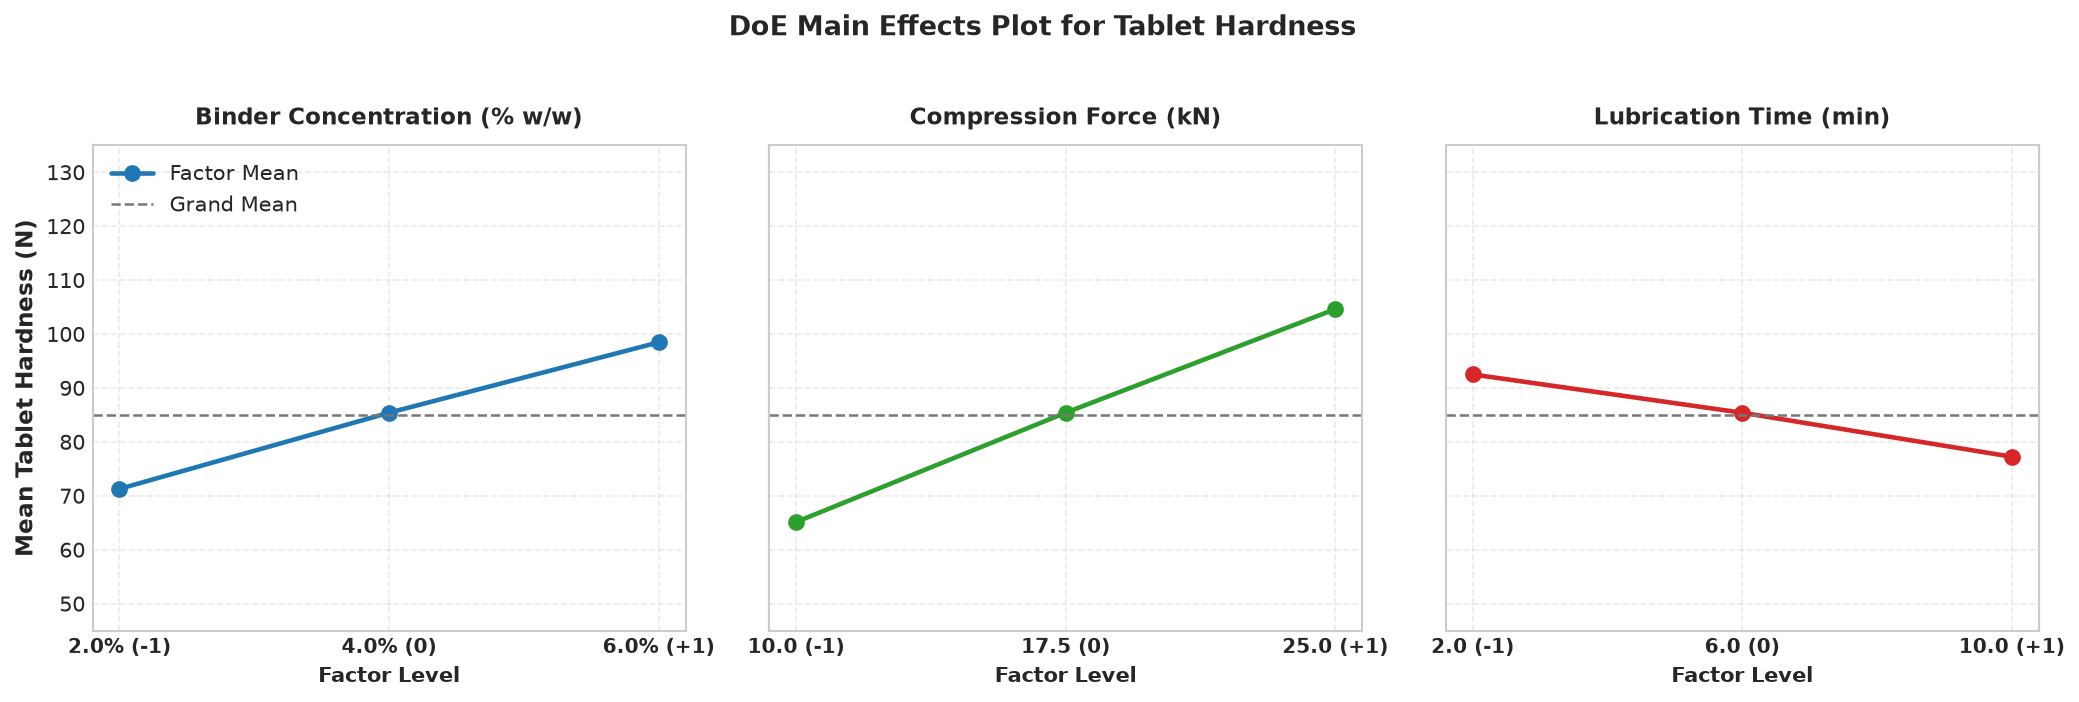

In [3]:
factors = [
    ("coded_A_binder", "Binder Concentration (% w/w)", ["2.0% (-1)", "4.0% (0)", "6.0% (+1)"]),
    ("coded_B_compression", "Compression Force (kN)", ["10.0 (-1)", "17.5 (0)", "25.0 (+1)"]),
    ("coded_C_lubrication", "Lubrication Time (min)", ["2.0 (-1)", "6.0 (0)", "10.0 (+1)"])
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), dpi=150, sharey=True)
overall_mean = df_doe["tablet_hardness_n"].mean()
colors = ["#1f77b4", "#2ca02c", "#d62728"]

for idx, (col, title, labels) in enumerate(factors):
    ax = axes[idx]
    means = df_doe.groupby(col)["tablet_hardness_n"].mean()
    levels = [-1, 0, 1]
    y_vals = [means.get(lvl, np.nan) for lvl in levels]

    ax.plot(levels, y_vals, marker="o", markersize=7, linewidth=2.2, color=colors[idx], label="Factor Mean")
    ax.axhline(overall_mean, color="#777777", linestyle="--", linewidth=1.2, label="Grand Mean")

    ax.set_xticks(levels)
    ax.set_xticklabels(labels, fontsize=9.5, fontweight="bold")
    ax.set_title(title, fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Factor Level", fontsize=10, fontweight="bold")
    if idx == 0:
        ax.set_ylabel("Mean Tablet Hardness (N)", fontsize=11, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_ylim(45, 135)

axes[0].legend(loc="upper left", framealpha=0.9)
plt.suptitle("DoE Main Effects Plot for Tablet Hardness", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

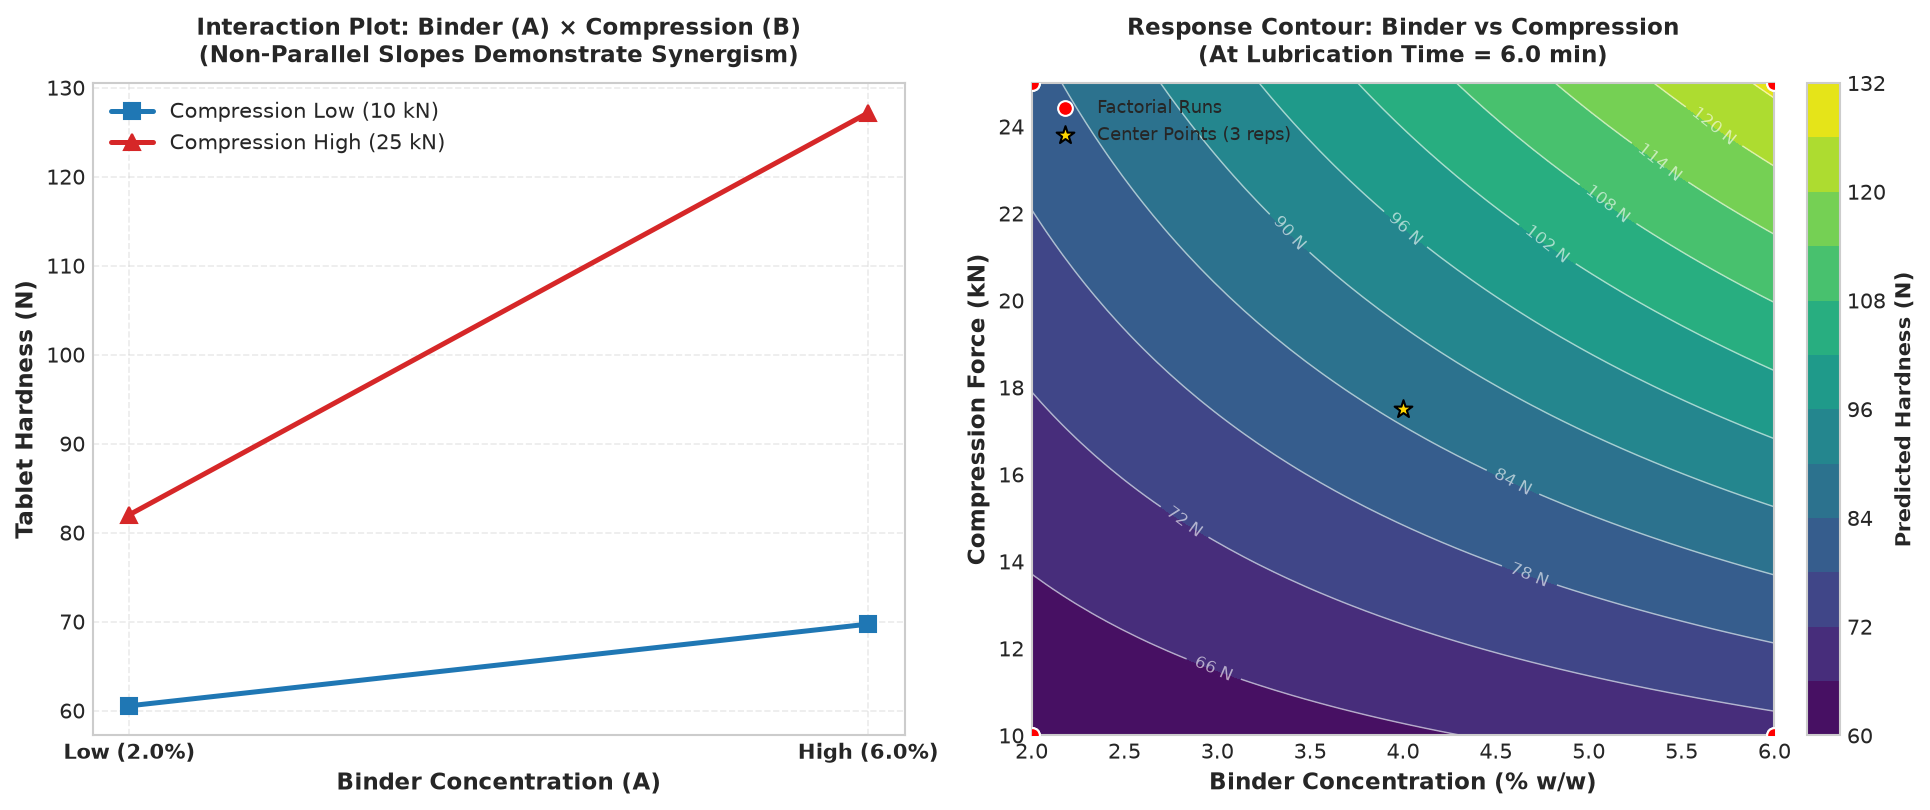

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), dpi=150)

# 1. Interaction Plot: Binder (A) * Compression (B)
fact_df = df_doe[df_doe["run_type"] == "Factorial"]
comp_low = fact_df[fact_df["coded_B_compression"] == -1].groupby("coded_A_binder")["tablet_hardness_n"].mean()
comp_high = fact_df[fact_df["coded_B_compression"] == 1].groupby("coded_A_binder")["tablet_hardness_n"].mean()

ax1.plot([-1, 1], [comp_low[-1], comp_low[1]], marker="s", markersize=8, linewidth=2.4, color="#1f77b4", label="Compression Low (10 kN)")
ax1.plot([-1, 1], [comp_high[-1], comp_high[1]], marker="^", markersize=8, linewidth=2.4, color="#d62728", label="Compression High (25 kN)")

ax1.set_xticks([-1, 1])
ax1.set_xticklabels(["Low (2.0%)", "High (6.0%)"], fontsize=10, fontweight="bold")
ax1.set_xlabel("Binder Concentration (A)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Tablet Hardness (N)", fontsize=11, fontweight="bold")
ax1.set_title("Interaction Plot: Binder (A) × Compression (B)\n(Non-Parallel Slopes Demonstrate Synergism)", fontsize=11, fontweight="bold", pad=10)
ax1.legend(loc="upper left", framealpha=0.9)
ax1.grid(True, linestyle="--", alpha=0.4)

# 2. Contour Plot of Response Surface at C = Center (6 min)
b0 = beta[0]
bA = beta[1]
bB = beta[2]
bAB = beta[4]

A_grid = np.linspace(-1, 1, 50)
B_grid = np.linspace(-1, 1, 50)
AA, BB = np.meshgrid(A_grid, B_grid)
ZZ = b0 + bA * AA + bB * BB + bAB * (AA * BB)

AA_natural = 4.0 + AA * 2.0
BB_natural = 17.5 + BB * 7.5

cs = ax2.contourf(AA_natural, BB_natural, ZZ, levels=12, cmap="viridis")
cbar = fig.colorbar(cs, ax=ax2, fraction=0.046, pad=0.04)
cbar.set_label("Predicted Hardness (N)", fontsize=10, fontweight="bold")

lines = ax2.contour(AA_natural, BB_natural, ZZ, levels=12, colors="white", linewidths=0.7, alpha=0.6)
ax2.clabel(lines, inline=True, fontsize=8, fmt="%1.0f N")

ax2.scatter(fact_df["binder_pct"], fact_df["compression_force_kn"], color="red", edgecolors="white", s=50, zorder=5, label="Factorial Runs")
ax2.scatter([4.0], [17.5], color="gold", edgecolors="black", s=80, marker="*", zorder=6, label="Center Points (3 reps)")

ax2.set_xlabel("Binder Concentration (% w/w)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Compression Force (kN)", fontsize=11, fontweight="bold")
ax2.set_title("Response Contour: Binder vs Compression\n(At Lubrication Time = 6.0 min)", fontsize=11, fontweight="bold", pad=10)
ax2.legend(loc="upper left", framealpha=0.85, fontsize=8.5)

plt.tight_layout()
plt.show()

### 3. Formulation Engineering Recommendations
1. **Design Space Target:** To target standard commercial tablet hardness of $90 - 100\text{ N}$, the operating parameters should be set to:
   * **Binder Concentration:** $4.0\% - 4.5\%$ (w/w)
   * **Compression Force:** $18.0 - 20.0\text{ kN}$
   * **Lubrication Blending Time:** strictly limited to $\le 4.0\text{ min}$ to avoid lubricant-induced softening.
2. **Process Control Window:** If high compression force ($25\text{ kN}$) is utilized, binder concentration must be kept below $5.0\%$ to prevent excessive hardness ($> 125\text{ N}$) and subsequent dissolution deceleration.